In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

RS = 42  # фиксируем случайность для воспроизводимости

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
print(X.shape, y.value_counts().to_dict())

(569, 30) {1: 357, 0: 212}


In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RS, stratify=y)

In [3]:
tree = DecisionTreeClassifier(random_state=RS).fit(X_train, y_train)
rf_default = RandomForestClassifier(random_state=RS).fit(X_train, y_train)

In [4]:
param_grid = {
    "n_estimators": [50, 100, 200, 300],
    "max_depth": [None, 5, 10],
    "min_samples_leaf": [1, 3, 5],
}
grid = GridSearchCV(
    RandomForestClassifier(random_state=RS, n_jobs=-1),
    param_grid, cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

best_params = grid.best_params_
rf_best = grid.best_estimator_
print("Лучшие параметры:", best_params)
print(f"CV accuracy: {grid.best_score_:.4f}")

Лучшие параметры: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}
CV accuracy: 0.9624


param_n_estimators
50     0.9577
100    0.9601
200    0.9601
300    0.9624
Name: mean_test_score, dtype: float64


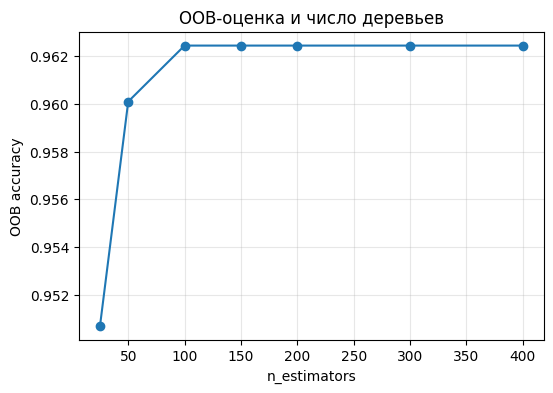

In [5]:
cv_res = pd.DataFrame(grid.cv_results_)
print(cv_res.groupby("param_n_estimators")["mean_test_score"].max().round(4))

n_list = [25, 50, 100, 150, 200, 300, 400]
oob = []
for n in n_list:
    m = RandomForestClassifier(
        n_estimators=n, max_depth=best_params["max_depth"],
        min_samples_leaf=best_params["min_samples_leaf"],
        oob_score=True, random_state=RS, n_jobs=-1).fit(X_train, y_train)
    oob.append(m.oob_score_)

plt.figure(figsize=(6, 4))
plt.plot(n_list, oob, marker="o")
plt.xlabel("n_estimators"); plt.ylabel("OOB accuracy")
plt.title("OOB-оценка и число деревьев"); plt.grid(alpha=.3)
plt.show()

In [6]:
rows = []
for name, mdl in [("Одиночное дерево", tree),
                  ("RF по умолчанию (100)", rf_default),
                  (f"RF настроенный ({best_params['n_estimators']})", rf_best)]:
    pred = mdl.predict(X_test)
    rows.append({"Модель": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})
print(pd.DataFrame(rows).round(4).to_string(index=False))

               Модель  Accuracy     F1
     Одиночное дерево    0.9231 0.9379
RF по умолчанию (100)    0.9580 0.9670
 RF настроенный (300)    0.9580 0.9670


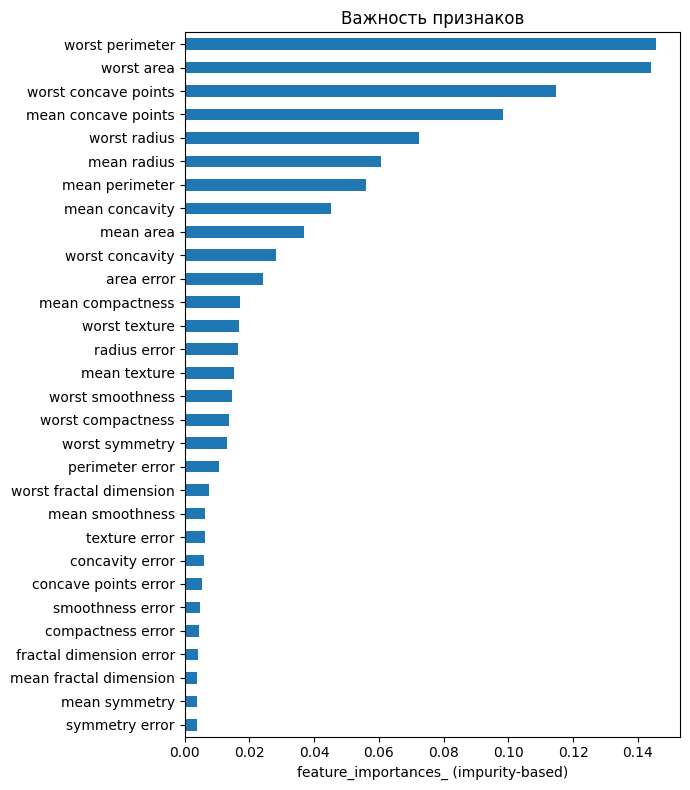

worst perimeter         0.1457
worst area              0.1441
worst concave points    0.1146
mean concave points     0.0983
worst radius            0.0724
dtype: float64


In [7]:
imp = pd.Series(rf_best.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(7, 8))
imp.plot.barh()
plt.xlabel("feature_importances_ (impurity-based)")
plt.title("Важность признаков")
plt.tight_layout(); plt.show()

print(imp.sort_values(ascending=False).head(5).round(4))

 Признаков  CV accuracy  CV std  Test accuracy
        30       0.9624  0.0203         0.9580
        25       0.9577  0.0243         0.9580
        20       0.9577  0.0191         0.9580
        15       0.9601  0.0206         0.9580
        10       0.9460  0.0242         0.9441
         7       0.9389  0.0252         0.9510
         5       0.9436  0.0203         0.9301
         3       0.9437  0.0188         0.9371
         2       0.9038  0.0226         0.8881


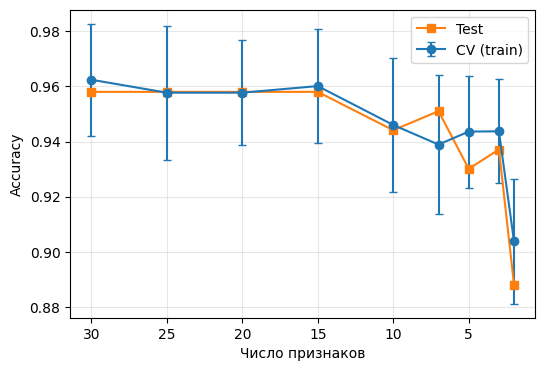

In [8]:
order = imp.sort_values(ascending=False).index.tolist()
ks = [30, 25, 20, 15, 10, 7, 5, 3, 2]
res = []
for k in ks:
    cols = order[:k]
    cv = cross_val_score(
        RandomForestClassifier(**best_params, random_state=RS, n_jobs=-1),
        X_train[cols], y_train, cv=5, scoring="accuracy")
    m = RandomForestClassifier(**best_params, random_state=RS, n_jobs=-1
                               ).fit(X_train[cols], y_train)
    res.append({"Признаков": k,
                "CV accuracy": cv.mean(), "CV std": cv.std(),
                "Test accuracy": accuracy_score(y_test, m.predict(X_test[cols]))})
res = pd.DataFrame(res).round(4)
print(res.to_string(index=False))

plt.figure(figsize=(6, 4))
plt.errorbar(res["Признаков"], res["CV accuracy"], yerr=res["CV std"],
             marker="o", capsize=3, label="CV (train)")
plt.plot(res["Признаков"], res["Test accuracy"], marker="s", label="Test")
plt.gca().invert_xaxis()
plt.xlabel("Число признаков"); plt.ylabel("Accuracy")
plt.legend(); plt.grid(alpha=.3); plt.show()

In [9]:
k_keep = 15  # выберите по таблице и графику шага 8
print("Оставляем:", order[:k_keep])
print("Можно исключить:", order[k_keep:])

Оставляем: ['worst perimeter', 'worst area', 'worst concave points', 'mean concave points', 'worst radius', 'mean radius', 'mean perimeter', 'mean concavity', 'mean area', 'worst concavity', 'area error', 'mean compactness', 'worst texture', 'radius error', 'mean texture']
Можно исключить: ['worst smoothness', 'worst compactness', 'worst symmetry', 'perimeter error', 'worst fractal dimension', 'mean smoothness', 'texture error', 'concavity error', 'concave points error', 'smoothness error', 'compactness error', 'fractal dimension error', 'mean fractal dimension', 'mean symmetry', 'symmetry error']
